In [1]:
%config InlineBackend.figure_format = 'retina'

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from cognitive_maps_in_llms.analysis import RunResults, plot_mosaic_series


In [2]:
REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'cognitive_maps_in_llms').is_dir()
)

# SET INPUT AND OUTPUT PATHS

# ------------------------------------------------------------------------------
RESULTS_ROOT = REPO_ROOT / 'results/final_run_2026-09-30'
FIGURES_DIR  = REPO_ROOT / 'figures/generated/main_text/figure_4'
SAVE_FIGURES = True
# ------------------------------------------------------------------------------

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
# DEFINE HELPER TO MAKE A SINGLE RETROSPECTIVE/PROSPECTIVE PLOT

MODEL_PRESET = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_yes_no'
EXPERIMENT = 'exp_4_retrospective_prospective'
STRUCTURE_PAIR = {
    'donor': 'A --rev--> B --fwd--> C',
    'control': 'A --fwd--> B --fwd--> C',
}
CONTROL_CONDITION = 'CTRL'
MOSAIC_CONDITION = 'ENTITY_RELATION_SPAN'
RESULTS = RunResults(results_root=RESULTS_ROOT)

def plot_figure_4_query(query: str, title: str, filename: str):
    control = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        structure_pair=STRUCTURE_PAIR,
        condition=CONTROL_CONDITION,
    )
    mosaic = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        structure_pair=STRUCTURE_PAIR,
        condition=MOSAIC_CONDITION,
    )

    plot = plot_mosaic_series(
        {'Control': control, 'Mosaic': mosaic},
        value_kind='probability_ratio',
        title=title,
        legend=False,
    )
    if SAVE_FIGURES:
        plot.save(FIGURES_DIR / filename)
    return plot


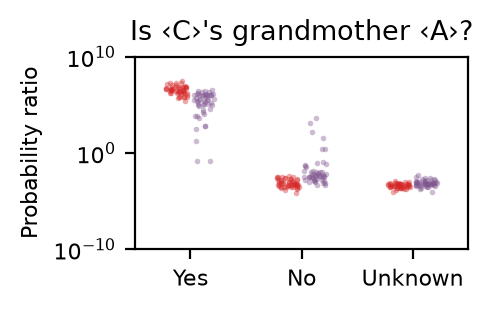

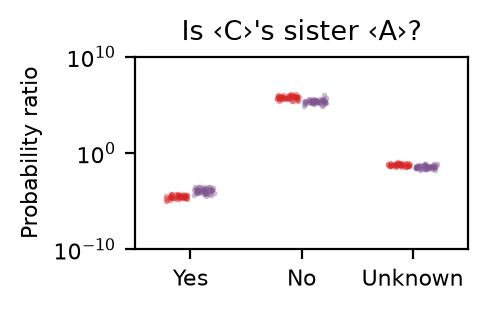

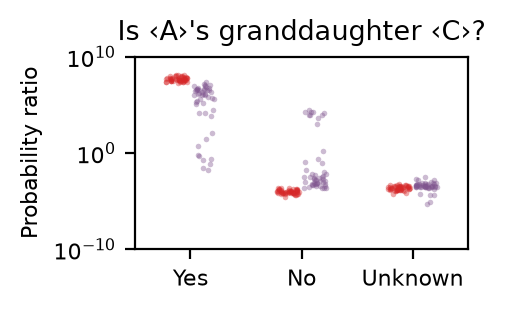

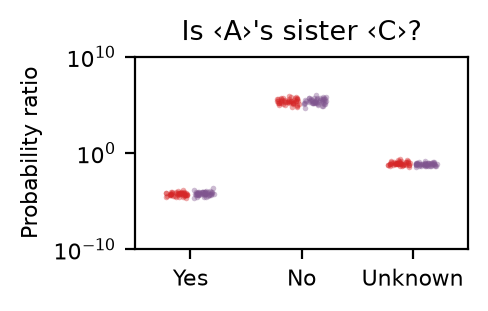

In [4]:
FIGURE_SPECS = (
    ('C --grandmother--> A?', "Is ‹C›'s grandmother ‹A›?", 'is_Cs_grandmother_A.svg'),
    ('C --sister--> A?', "Is ‹C›'s sister ‹A›?", 'is_Cs_sister_A.svg'),
    ('A --granddaughter--> C?', "Is ‹A›'s granddaughter ‹C›?", 'is_As_granddaughter_C.svg'),
    ('A --sister--> C?', "Is ‹A›'s sister ‹C›?", 'is_As_sister_C.svg'),
)

for query, title, filename in FIGURE_SPECS:
    plot = plot_figure_4_query(query, title, filename)
    display(plot.fig)
    plt.close(plot.fig)
